### MiniZinc 3: Zuordnen und Planen - Übungen

Viele Planungsaufgaben im Alltag sind **Zuordnungen**: Wer bekommt welches Referatsthema? Wer sitzt wo? Wer hat an welchem Tag Pausenaufsicht?
Wer fährt mit wem zusammen? In diesem Notebook modellierst du solche Aufgaben mit globalen Constraints wie `alldifferent` und `global_cardinality`,
lernst, wie man doppelte Lösungen vermeidet, und was man tun kann, wenn der Solver zu lange rechnet.

Die Reihe hat drei Notebooks:

1. Grundlagen: Modelle, Variablen, Bedingungen, Optimieren
2. Daten: Aufzählungen, Arrays, Datendateien, Mengen
3. **Zuordnen und Planen**: Zuordnungen, Sitz- und Dienstpläne, Gruppen (dieses Notebook)

Vorausgesetzt werden *MiniZinc: Grundlagen* und *MiniZinc: Daten*.

**Dieses Notebook ist ein Arbeitsblatt.** MiniZinc läuft weder im Browser-Python der Übungsseite noch in Colab. Die Codezellen enthalten
MiniZinc-Code, keinen Python-Code: **Führe sie hier nicht aus**, sondern kopiere sie. Lies die Erklärungen hier und schreibe und starte die Modelle in der **MiniZinc IDE**
(kostenlos für Windows, macOS und Linux: [minizinc.org](https://www.minizinc.org/)). Ohne Installation geht es auch im Browser im
[MiniZinc Playground](https://play.minizinc.org/).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Tippe die Beispiele in der IDE ab (oder kopiere sie) und probiere sie aus.
Danach folgen kleine Übungen mit der erwarteten Ausgabe. Unter jeder Aufgabe steht eine Codezelle für deine Lösung: Schreib sie dort hinein,
damit du sie später nachlesen kannst, und führe sie in der MiniZinc IDE aus.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst in der MiniZinc IDE!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann das Modell in der IDE aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

## 1. Zuordnungen mit alldifferent

#### Jedem genau ein Thema

Vier Schülerinnen und Schüler halten ein Referat; es gibt sechs Themen, und jedes Thema darf nur einmal vergeben werden. Jede und jeder hat jedes Thema mit 1 bis 10
bewertet. Gesucht ist die Zuordnung mit der größten Gesamtzufriedenheit.

Gesucht ist eine **Funktion**: `thema[s]` ist das Thema von `s`. Dass kein Thema doppelt vergeben wird, sagt `alldifferent(thema)`.
Der Wunschwert von `s` ist `wunsch[s, thema[s]]`: Der zweite Index ist eine Entscheidungsvariable (wie in *Grundlagen*, Abschnitt 7).
Wie `sum(s in SCHUELER)(...)` funktionieren auch `max(s in SCHUELER)(...)` und `min(s in SCHUELER)(...)`.

In [ ]:
include "alldifferent.mzn";

enum SCHUELER = {ANNA, BEN, CEM, DANA};
enum THEMA = {VULKANE, WALE, PYRAMIDEN, PLANETEN, DINOSAURIER, ROBOTER};

array[SCHUELER, THEMA] of int: wunsch = [| 7, 10, 3,  5, 2,  8
                                         | 4,  6, 2,  5, 1,  5
                                         | 7,  9, 5, 10, 7,  9
                                         | 4,  9, 6,  1, 7, 10 |];

array[SCHUELER] of var THEMA: thema;

var int: zufrieden = sum(s in SCHUELER)(wunsch[s, thema[s]]);

constraint alldifferent(thema);

solve maximize zufrieden;

output ["\(s): \(thema[s]) (\(wunsch[s, thema[s]]))\n" | s in SCHUELER] ++ ["Summe: \(zufrieden)\n"];

**Ausgabe:**

```
ANNA: WALE (10)
BEN: VULKANE (4)
CEM: PLANETEN (10)
DANA: ROBOTER (10)
Summe: 34
----------
==========
```

#### Aufgabe 1.1

Ändere das Referate-Modell so, dass das **unzufriedenste** Kind möglichst zufrieden ist: Maximiere das Minimum der Wunschwerte
(`var int: schlechtester = min(s in SCHUELER)(wunsch[s, thema[s]]);`). Bei gleichem Minimum soll die Summe entscheiden: `solve maximize 100 * schlechtester + summe;`.
Gib die Zuordnung aus wie im Beispiel und danach `Minimum: ...`.

**Erwartete Ausgabe:**

```
ANNA: VULKANE (7)
BEN: WALE (6)
CEM: PLANETEN (10)
DANA: ROBOTER (10)
Minimum: 6
----------
==========
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum SCHUELER = {ANNA, BEN, CEM, DANA};
enum THEMA = {VULKANE, WALE, PYRAMIDEN, PLANETEN, DINOSAURIER, ROBOTER};

array[SCHUELER, THEMA] of int: wunsch = [| 7, 10, 3,  5, 2,  8
                                         | 4,  6, 2,  5, 1,  5
                                         | 7,  9, 5, 10, 7,  9
                                         | 4,  9, 6,  1, 7, 10 |];

array[SCHUELER] of var THEMA: thema;

var int: summe = sum(s in SCHUELER)(wunsch[s, thema[s]]);
var int: schlechtester = min(s in SCHUELER)(wunsch[s, thema[s]]);

constraint alldifferent(thema);

solve maximize 100 * schlechtester + summe;

output ["\(s): \(thema[s]) (\(wunsch[s, thema[s]]))\n" | s in SCHUELER] ++ ["Minimum: \(schlechtester)\n"];
```

</details>

#### Aufgabe 1.2

Die Themen Vulkane und Dinosaurier passen gut zusammen und sollen **beide** vergeben werden, Roboter dagegen gar nicht. Ergänze das Beispielmodell (Summe maximieren).

**Erwartete Ausgabe:**

```
ANNA: WALE (10)
BEN: VULKANE (4)
CEM: PLANETEN (10)
DANA: DINOSAURIER (7)
Summe: 31
----------
==========
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum SCHUELER = {ANNA, BEN, CEM, DANA};
enum THEMA = {VULKANE, WALE, PYRAMIDEN, PLANETEN, DINOSAURIER, ROBOTER};

array[SCHUELER, THEMA] of int: wunsch = [| 7, 10, 3,  5, 2,  8
                                         | 4,  6, 2,  5, 1,  5
                                         | 7,  9, 5, 10, 7,  9
                                         | 4,  9, 6,  1, 7, 10 |];

array[SCHUELER] of var THEMA: thema;

var int: zufrieden = sum(s in SCHUELER)(wunsch[s, thema[s]]);

constraint alldifferent(thema);
constraint exists(s in SCHUELER)(thema[s] = VULKANE);
constraint exists(s in SCHUELER)(thema[s] = DINOSAURIER);
constraint forall(s in SCHUELER)(thema[s] != ROBOTER);

solve maximize zufrieden;

output ["\(s): \(thema[s]) (\(wunsch[s, thema[s]]))\n" | s in SCHUELER] ++ ["Summe: \(zufrieden)\n"];
```

</details>

#### Aufgabe 1.3

Vier Aufgaben im Klassendienst (Tafel, Blumen, Müll, Fenster) werden auf vier Kinder verteilt. Wie lange jedes Kind für jede Aufgabe braucht (Minuten), steht in

```minizinc
enum KIND = {ANNA, BEN, CEM, DANA};
enum DIENST = {TAFEL, BLUMEN, MUELL, FENSTER};
array[KIND, DIENST] of int: minuten = [| 6, 7, 2, 9
                                       | 5, 2, 4, 3
                                       | 7, 9, 5, 8
                                       | 3, 5, 2, 5 |];
```

Jedes Kind bekommt genau einen Dienst. Die Summe der Minuten soll möglichst klein sein. Gib `KIND: DIENST` zeilenweise und die Summe aus (`Summe: ... Minuten`).

**Erwartete Ausgabe:**

```
ANNA: MUELL
BEN: BLUMEN
CEM: FENSTER
DANA: TAFEL
Summe: 15 Minuten
----------
==========
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum KIND = {ANNA, BEN, CEM, DANA};
enum DIENST = {TAFEL, BLUMEN, MUELL, FENSTER};
array[KIND, DIENST] of int: minuten = [| 6, 7, 2, 9
                                       | 5, 2, 4, 3
                                       | 7, 9, 5, 8
                                       | 3, 5, 2, 5 |];

array[KIND] of var DIENST: dienst;
var int: summe = sum(k in KIND)(minuten[k, dienst[k]]);

constraint alldifferent(dienst);

solve minimize summe;

output ["\(k): \(dienst[k])\n" | k in KIND] ++ ["Summe: \(summe) Minuten\n"];
```

</details>

#### Aufgabe 1.4

Beim Klassendienst aus der vorigen Aufgabe soll nun die Dauer des **längsten** Dienstes möglichst kurz sein (alle sind gleichzeitig fertig, wenn der langsamste fertig ist).
Bei gleicher längster Dauer entscheidet die Summe (`solve minimize 100 * laengster + summe;`). Gib die Zuordnung und `Längster Dienst: ... Minuten` aus.

**Erwartete Ausgabe:**

```
ANNA: TAFEL
BEN: BLUMEN
CEM: MUELL
DANA: FENSTER
Längster Dienst: 6 Minuten
----------
==========
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum KIND = {ANNA, BEN, CEM, DANA};
enum DIENST = {TAFEL, BLUMEN, MUELL, FENSTER};
array[KIND, DIENST] of int: minuten = [| 6, 7, 2, 9
                                       | 5, 2, 4, 3
                                       | 7, 9, 5, 8
                                       | 3, 5, 2, 5 |];

array[KIND] of var DIENST: dienst;
var int: summe = sum(k in KIND)(minuten[k, dienst[k]]);
var int: laengster = max(k in KIND)(minuten[k, dienst[k]]);

constraint alldifferent(dienst);

solve minimize 100 * laengster + summe;

output ["\(k): \(dienst[k])\n" | k in KIND] ++ ["Längster Dienst: \(laengster) Minuten\n"];
```

</details>

#### Aufgabe 1.5

Was gibt das Modell in der Zelle unten aus? Überlege zuerst, führe es dann in der MiniZinc IDE aus und vergleiche.

In [ ]:
include "alldifferent.mzn";

array[1..3, 1..3] of int: punkte = [| 5, 1, 1
                                     | 1, 5, 1
                                     | 1, 1, 5 |];

array[1..3] of var 1..3: wahl;

constraint alldifferent(wahl);

solve maximize sum(i in 1..3)(punkte[i, wahl[i]]);

output ["\(wahl)\n"];

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[1, 2, 3]
----------
==========
```

Die 5 Punkte stehen auf der Diagonalen. Gibt jede Zeile `i` die Spalte `i` an, gibt es `5 + 5 + 5 = 15` Punkte, mehr geht nicht:
Ausgabe `[1, 2, 3]`, danach `----------` und `==========` (das Optimum ist bewiesen).

</details>

## 2. Plätze im Raster: ein Sitzplan

#### Zwei Koordinaten pro Person

Acht Schülerinnen und Schüler sollen auf einen Raum mit 2 Reihen zu je 4 Plätzen verteilt werden. Jede Person bekommt eine Reihe `r[s]` und einen Platz `p[s]`.
Zwei Personen dürfen nicht auf denselben Platz: Jeder Platz hat eine eigene Nummer `(r - 1) · 4 + p`, und diese Nummern müssen verschieden sein.

Weitere Regeln:
- Wer eine Brille braucht, sitzt in Reihe 1.
- Zwei, die viel reden (ALI und CEM), sitzen nicht **nebeneinander** und nicht **hintereinander**: Der Abstand `abs(r[a] - r[b]) + abs(p[a] - p[b])` ist größer als 1
  (`abs(x)` ist der Betrag von `x`).

Die Ausgabe geht alle Plätze Reihe für Reihe durch und schreibt den Namen der Person, die dort sitzt (für alle anderen Personen den leeren Text `""`).

Es gibt viele erlaubte Sitzpläne; deiner sieht vermutlich anders aus.

In [ ]:
include "alldifferent.mzn";

enum SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
set of int: REIHE = 1..2;
set of int: PLATZ = 1..4;
set of SCHUELER: brille = {BEA, GUS};

array[SCHUELER] of var REIHE: r;
array[SCHUELER] of var PLATZ: p;

constraint alldifferent([(r[s] - 1) * 4 + p[s] | s in SCHUELER]);
constraint forall(s in brille)(r[s] = 1);
constraint abs(r[ALI] - r[CEM]) + abs(p[ALI] - p[CEM]) > 1;

solve satisfy;

output [if fix(r[s]) = i /\ fix(p[s]) = j then show(s) ++ " " else "" endif | i in REIHE, j in PLATZ, s in SCHUELER] ++ ["\n"];

**Ausgabe:**

```
CEM GUS ALI BEA HANNA FIONA EMIL DANA 
----------
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

#### Aufgabe 2.1

Gib im Sitzplan-Modell die Belegung als Tabelle aus: für jede Reihe eine Zeile mit den vier Namen in der Reihenfolge der Plätze, durch Leerzeichen getrennt
(Tipp: wie im Beispiel, aber nach Platz 4 ein Zeilenumbruch statt eines Leerzeichens). Regeln:
- DANA sitzt in Reihe 1 auf Platz 1, EMIL direkt rechts neben ihr (Platz 2), FIONA direkt hinter DANA.
- ALI und BEA sitzen in Reihe 1.
- Alle außer DANA, EMIL und FIONA sitzen innerhalb ihrer Reihe alphabetisch von links nach rechts. Die Aufzählung ist alphabetisch, deshalb kannst du
  Personen mit `<` vergleichen: `ALI < BEA` ist wahr.

**Erwartete Ausgabe:**

```
DANA EMIL ALI BEA
FIONA CEM GUS HANNA
----------
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
set of int: REIHE = 1..2;
set of int: PLATZ = 1..4;

array[SCHUELER] of var REIHE: r;
array[SCHUELER] of var PLATZ: p;

constraint alldifferent([(r[s] - 1) * 4 + p[s] | s in SCHUELER]);

constraint r[DANA] = 1 /\ p[DANA] = 1;
constraint r[EMIL] = 1 /\ p[EMIL] = 2;
constraint r[FIONA] = 2 /\ p[FIONA] = 1;
constraint r[ALI] = 1 /\ r[BEA] = 1;
constraint forall(s, u in SCHUELER where s < u /\ not (s in {DANA, EMIL, FIONA}) /\ not (u in {DANA, EMIL, FIONA}))(
    r[s] = r[u] -> p[s] < p[u]
);

solve satisfy;

output [if fix(r[s]) = i /\ fix(p[s]) = j then show(s) ++ if j = 4 then "\n" else " " endif else "" endif
        | i in REIHE, j in PLATZ, s in SCHUELER];
```

</details>

#### Aufgabe 2.2

Die Klasse hat Freundespaare, die gern **nebeneinander** sitzen (gleiche Reihe, Plätze direkt nebeneinander):

```minizinc
array[1..8, 1..2] of SCHUELER: freunde = [| ALI, BEA | BEA, CEM | CEM, DANA | DANA, EMIL
                                         | EMIL, FIONA | FIONA, GUS | GUS, HANNA | HANNA, ALI |];
```

Wie im Beispiel sitzen BEA und GUS in Reihe 1, und ALI und CEM sitzen nicht nebeneinander oder hintereinander. Wie viele Freundespaare können höchstens nebeneinander sitzen?
Gib nur `Paare: ...` aus (es gibt mehrere gleich gute Sitzpläne).

**Erwartete Ausgabe:**

```
Paare: 6
----------
==========
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
set of int: REIHE = 1..2;
set of int: PLATZ = 1..4;

array[SCHUELER] of var REIHE: r;
array[SCHUELER] of var PLATZ: p;

constraint alldifferent([(r[s] - 1) * 4 + p[s] | s in SCHUELER]);
array[1..8, 1..2] of SCHUELER: freunde = [| ALI, BEA | BEA, CEM | CEM, DANA | DANA, EMIL
                                         | EMIL, FIONA | FIONA, GUS | GUS, HANNA | HANNA, ALI |];

constraint r[BEA] = 1 /\ r[GUS] = 1;
constraint abs(r[ALI] - r[CEM]) + abs(p[ALI] - p[CEM]) > 1;

var int: paare = sum(i in 1..8)(r[freunde[i, 1]] = r[freunde[i, 2]] /\ abs(p[freunde[i, 1]] - p[freunde[i, 2]]) = 1);

solve maximize paare;

output ["Paare: \(paare)\n"];
```

</details>

#### Aufgabe 2.3

Wie viele Sitzpläne gibt es, wenn BEA und GUS in Reihe 1 sitzen müssen und ALI und CEM nicht nebeneinander oder hintereinander sitzen dürfen (das Modell aus dem Beispiel)?

**Erwartete Ausgabe:**

**Anzahl der Lösungen: 5472**

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
set of int: REIHE = 1..2;
set of int: PLATZ = 1..4;
set of SCHUELER: brille = {BEA, GUS};

array[SCHUELER] of var REIHE: r;
array[SCHUELER] of var PLATZ: p;

constraint alldifferent([(r[s] - 1) * 4 + p[s] | s in SCHUELER]);
constraint forall(s in brille)(r[s] = 1);
constraint abs(r[ALI] - r[CEM]) + abs(p[ALI] - p[CEM]) > 1;

solve satisfy;
```

</details>

#### Aufgabe 2.4

Was gibt das Modell in der Zelle unten aus? Überlege zuerst, führe es dann in der MiniZinc IDE aus und vergleiche.

In [ ]:
array[1..3] of int: r = [1, 2, 1];
array[1..3] of int: p = [2, 2, 4];

output ["\(abs(r[1] - r[2]) + abs(p[1] - p[2])) \(abs(r[1] - r[3]) + abs(p[1] - p[3]))\n",
        "\([(r[i] - 1) * 4 + p[i] | i in 1..3])\n"];

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
1 2
[2, 6, 4]
----------
```

- Person 1 (Reihe 1, Platz 2) und Person 2 (Reihe 2, Platz 2) sitzen hintereinander: Abstand `1 + 0 = 1`. Person 1 und 3 sitzen in derselben Reihe zwei Plätze auseinander: `0 + 2 = 2`.
- Die Platznummern `(r - 1) · 4 + p` sind 2, 6 und 4: `[2, 6, 4]`.

</details>

## 3. Dienstpläne mit global_cardinality

#### Wie oft kommt jeder Wert vor?

Fünf Lehrkräfte teilen sich an fünf Tagen die Pausenaufsicht. Jeden Tag braucht man **genau zwei** Lehrkräfte auf dem Hof und **genau eine** im Flur; die übrigen haben frei.
Niemand soll an zwei aufeinanderfolgenden Tagen Hofaufsicht haben.

`array[LEHRKRAFT, TAG] of var DIENST: plan;` ist ein 2D-Array von Variablen. Für das Zählen gibt es den globalen Constraint
`global_cardinality(x, werte, anzahlen)`: In der Liste `x` kommt `werte[i]` genau `anzahlen[i]`-mal vor. Andere Werte (hier `FREI`) dürfen beliebig oft vorkommen.
`[plan[l, t] | l in LEHRKRAFT]` ist die Spalte eines Tages.

In der Ausgabe schreibt `format(-5, x)` den Wert `x` linksbündig mit 5 Zeichen Breite (mit Leerzeichen aufgefüllt), damit die Spalten untereinander stehen.

Es gibt sehr viele gültige Pläne; deiner sieht vermutlich anders aus.

In [ ]:
include "globals.mzn";

enum LEHRKRAFT = {KOCH, LANG, MEYER, NAGEL, OTT};
enum DIENST = {FREI, HOF, FLUR};
set of int: TAG = 1..5;

array[LEHRKRAFT, TAG] of var DIENST: plan;

constraint forall(t in TAG)(
    global_cardinality([plan[l, t] | l in LEHRKRAFT], [HOF, FLUR], [2, 1])
);
constraint forall(l in LEHRKRAFT, t in 1..4)(
    plan[l, t] = HOF -> plan[l, t + 1] != HOF
);

solve satisfy;

output [if t = 1 then format(-6, l) else "" endif ++ format(-5, plan[l, t]) ++ if t = 5 then "\n" else "" endif
        | l in LEHRKRAFT, t in TAG];

**Ausgabe:**

```
KOCH  FLUR HOF  FLUR HOF  FLUR 
LANG  HOF  FLUR HOF  FLUR HOF  
MEYER HOF  FREI HOF  FREI HOF  
NAGEL FREI HOF  FREI HOF  FREI 
OTT   FREI FREI FREI FREI FREI 
----------
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

#### Aufgabe 3.1

Wie viele Aufsichten (Hof oder Flur) hat jede Lehrkraft? Ergänze das Modell um `array[LEHRKRAFT] of var 0..5: anzahl;` mit
`anzahl[l] = sum(t in TAG)(plan[l, t] != FREI)` und sorge für **Gerechtigkeit**: Die größte Anzahl soll möglichst klein sein (`solve minimize max(anzahl);`).
Gib nur das Ergebnis `Höchstens ... Aufsichten pro Lehrkraft` aus (es gibt viele gleich gute Pläne).

**Erwartete Ausgabe:**

```
Höchstens 3 Aufsichten pro Lehrkraft
----------
==========
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum LEHRKRAFT = {KOCH, LANG, MEYER, NAGEL, OTT};
enum DIENST = {FREI, HOF, FLUR};
set of int: TAG = 1..5;

array[LEHRKRAFT, TAG] of var DIENST: plan;

constraint forall(t in TAG)(
    global_cardinality([plan[l, t] | l in LEHRKRAFT], [HOF, FLUR], [2, 1])
);
constraint forall(l in LEHRKRAFT, t in 1..4)(
    plan[l, t] = HOF -> plan[l, t + 1] != HOF
);

array[LEHRKRAFT] of var 0..5: anzahl;
constraint forall(l in LEHRKRAFT)(anzahl[l] = sum(t in TAG)(plan[l, t] != FREI));

solve minimize max(anzahl);

output ["Höchstens \(max(anzahl)) Aufsichten pro Lehrkraft\n"];
```

</details>

#### Aufgabe 3.2

Ergänze das Dienstplan-Modell um Wünsche: KOCH hat montags (Tag 1) frei, LANG macht nie Flurdienst, und MEYER hat an Tag 3 Hofaufsicht. Ist das noch lösbar?
Gib den Plan wie im Beispiel aus (es gibt mehrere Lösungen).

**Erwartete Ausgabe:**

```
KOCH  FREI HOF  FLUR HOF  FLUR 
LANG  FREI FREI FREI FREI FREI 
MEYER HOF  FLUR HOF  FREI HOF  
NAGEL FLUR HOF  FREI HOF  FREI 
OTT   HOF  FREI HOF  FLUR HOF  
----------
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum LEHRKRAFT = {KOCH, LANG, MEYER, NAGEL, OTT};
enum DIENST = {FREI, HOF, FLUR};
set of int: TAG = 1..5;

array[LEHRKRAFT, TAG] of var DIENST: plan;

constraint forall(t in TAG)(
    global_cardinality([plan[l, t] | l in LEHRKRAFT], [HOF, FLUR], [2, 1])
);
constraint forall(l in LEHRKRAFT, t in 1..4)(
    plan[l, t] = HOF -> plan[l, t + 1] != HOF
);

constraint plan[KOCH, 1] = FREI;
constraint forall(t in TAG)(plan[LANG, t] != FLUR);
constraint plan[MEYER, 3] = HOF;

solve satisfy;

output [if t = 1 then format(-6, l) else "" endif ++ format(-5, plan[l, t]) ++ if t = 5 then "\n" else "" endif
        | l in LEHRKRAFT, t in TAG];
```

</details>

#### Aufgabe 3.3

Jede Lehrkraft soll genau **einmal** in der Woche Flurdienst haben und genau zweimal Hofdienst. Statt `global_cardinality` pro Tag brauchst du jetzt **zusätzlich**
für jede Lehrkraft `global_cardinality([plan[l, t] | t in TAG], [HOF, FLUR], [2, 1])`. Wie viele Pläne gibt es dann?

**Erwartete Ausgabe:**

**Anzahl der Lösungen: 2280**

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum LEHRKRAFT = {KOCH, LANG, MEYER, NAGEL, OTT};
enum DIENST = {FREI, HOF, FLUR};
set of int: TAG = 1..5;

array[LEHRKRAFT, TAG] of var DIENST: plan;

constraint forall(t in TAG)(
    global_cardinality([plan[l, t] | l in LEHRKRAFT], [HOF, FLUR], [2, 1])
);
constraint forall(l in LEHRKRAFT, t in 1..4)(
    plan[l, t] = HOF -> plan[l, t + 1] != HOF
);

constraint forall(l in LEHRKRAFT)(
    global_cardinality([plan[l, t] | t in TAG], [HOF, FLUR], [2, 1])
);

solve satisfy;
```

</details>

#### Aufgabe 3.4

Was gibt das Modell in der Zelle unten aus? Überlege zuerst, führe es dann in der MiniZinc IDE aus und vergleiche.

In [ ]:
include "globals.mzn";

array[1..4] of var 1..3: x;

constraint global_cardinality(x, [1, 2], [3, 0]);
constraint x[1] != 1;

solve satisfy;

output ["\(x)\n"];

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[3, 1, 1, 1]
----------
```

Der Wert 1 muss genau dreimal vorkommen, der Wert 2 gar nicht. Also bleibt für die vierte Stelle nur die 3. Weil `x[1]` nicht 1 ist, steht die 3 vorne:
Ausgabe `[3, 1, 1, 1]`, danach `----------`.

</details>

## 4. Wenn der Solver lange rechnet

#### Tipps für schnellere Modelle

Constraint-Probleme können sehr schwer werden: Die Zahl der möglichen Belegungen wächst mit jeder Variablen stark an. Rechnet der Solver zu lange, stoppst du ihn
in der IDE mit dem roten *Stop*-Knopf. Dann helfen oft diese Änderungen:

1. **Kleine Wertebereiche:** `var 0..20: x;` statt `var int: x;`. Je weniger Werte, desto weniger muss probiert werden.
2. **Globale Constraints** statt vieler einzelner Bedingungen: `alldifferent`, `global_cardinality` usw. kennen schlaue Verfahren, die viele Belegungen auf einmal ausschließen.
3. **Zwischenvariablen** für Ausdrücke, die mehrfach vorkommen, z. B. `array[TAG] of var 0..5: anzahl;` statt dieselbe Summe an mehreren Stellen.
4. **Symmetrien brechen:** Wenn viele Lösungen im Grunde gleich sind (z. B. nur anders nummeriert), schließt man alle bis auf eine aus (Abschnitt 5).
5. **Einen anderen Solver** ausprobieren: In der Auswahlliste der Solver (Konfigurationseditor der IDE) kann man statt Gecode z. B. **Chuffed** oder
   **OR Tools CP-SAT** wählen. Bei Optimierungsproblemen sind sie oft viel schneller. Für Probleme mit Kommazahlen eignen sich **HiGHS** oder **COIN-BC**.

Wie lange gerechnet wurde, zeigt der Haken *Output timing information* im Konfigurationseditor; *Output solving statistics* zeigt außerdem, wie viele
Belegungen probiert wurden (`nodes`).

#### Aufgabe 4.1

Verlängere das Dienstplan-Modell mit der **Gerechtigkeit** (Aufgabe 3.1) auf 10 Tage und 8 Lehrkräfte (PAUL, QUAST, ROTH kommen dazu). Löse es mit Gecode,
Chuffed und OR Tools CP-SAT und vergleiche die Zeiten. Beim Testen hatten Gecode und Chuffed nach einer Minute noch kein bewiesenes Optimum gefunden,
OR Tools CP-SAT brauchte etwa zwei Sekunden. Gib wie in Aufgabe 3.1 nur das Ergebnis aus.

**Erwartete Ausgabe:**

```
Höchstens 4 Aufsichten pro Lehrkraft
----------
==========
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum LEHRKRAFT = {KOCH, LANG, MEYER, NAGEL, OTT, PAUL, QUAST, ROTH};
enum DIENST = {FREI, HOF, FLUR};
set of int: TAG = 1..10;

array[LEHRKRAFT, TAG] of var DIENST: plan;
array[LEHRKRAFT] of var 0..10: anzahl;

constraint forall(t in TAG)(
    global_cardinality([plan[l, t] | l in LEHRKRAFT], [HOF, FLUR], [2, 1])
);
constraint forall(l in LEHRKRAFT, t in 1..9)(
    plan[l, t] = HOF -> plan[l, t + 1] != HOF
);
constraint forall(l in LEHRKRAFT)(anzahl[l] = sum(t in TAG)(plan[l, t] != FREI));

solve minimize max(anzahl);

output ["Höchstens \(max(anzahl)) Aufsichten pro Lehrkraft\n"];
```

</details>

## 5. Gruppen bilden und Symmetrien brechen

#### Fahrgemeinschaften

Acht Schülerinnen und Schüler wohnen an den Orten in der Skizze (Koordinaten in km). Sie sollen in **drei Fahrgemeinschaften** aufgeteilt werden; in einer Gruppe
dürfen zwei Wohnorte höchstens 3 km voneinander entfernt sein. `gruppe[s]` ist die Nummer der Fahrgemeinschaft von `s`.

Den Abstand berechnet man mit Pythagoras. Weil MiniZinc hier mit ganzen Zahlen rechnet, vergleicht man die **Quadrate**: `abstand² <= 3²`.
`array2d(SCHUELER, SCHUELER, [...])` macht aus einer Liste mit 64 Werten ein 2D-Array.

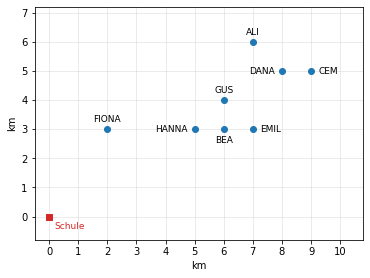

In [ ]:
include "globals.mzn";

enum SCHUELER;
array[SCHUELER] of int: x;
array[SCHUELER] of int: y;
int: k = 3;                                    % Anzahl der Fahrgemeinschaften
set of int: GRUPPE = 1..k;
int: maxabstand = 3;                           % in einer Gruppe höchstens 3 km voneinander entfernt

% Quadrat des Abstands zweier Wohnorte (ganze Zahlen, deshalb ohne Wurzel)
array[SCHUELER, SCHUELER] of int: abstand2 = array2d(SCHUELER, SCHUELER,
    [(x[a] - x[b]) * (x[a] - x[b]) + (y[a] - y[b]) * (y[a] - y[b]) | a, b in SCHUELER]);

array[SCHUELER] of var GRUPPE: gruppe;

constraint forall(a, b in SCHUELER where a < b)(
    gruppe[a] = gruppe[b] -> abstand2[a, b] <= maxabstand * maxabstand
);

solve satisfy;

output ["\(gruppe)\n"];

Daten (Datei `wohnorte.dzn`):

In [ ]:
SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
x = [7, 6, 9, 8, 7, 2, 6, 5];
y = [6, 3, 5, 5, 3, 3, 4, 3];

**Ausgabe:**

```
[2, 3, 2, 2, 2, 1, 3, 1]
----------
```

*Eine von mehreren möglichen Lösungen: Dein Solver findet vielleicht eine andere.*

#### Symmetrien: dieselbe Einteilung, andere Nummern

Die Lösung oben `[2, 3, 2, 2, 2, 1, 3, 1]` und `[1, 2, 1, 1, 1, 3, 2, 3]` sind **dieselbe** Einteilung, nur die Gruppen heißen anders. Solche **Symmetrien** vervielfachen die Zahl der
Lösungen und machen die Suche langsam. Man bricht sie, indem man eine **feste Reihenfolge** verlangt: Gruppe 1 ist die Gruppe der ersten Person, Gruppe 2 kommt erst vor,
nachdem Gruppe 1 vorgekommen ist, usw. Genau das macht der globale Constraint `value_precede_chain(GRUPPE, gruppe)`.

Das Modell unten zählt die Einteilungen (mit *Print all solutions*). Mit `value_precede_chain` gibt es nur noch eine Lösung pro echter Einteilung.
Kommentiere die Zeile mit `%` aus und vergleiche (Aufgabe 5.1).

In [ ]:
include "globals.mzn";

enum SCHUELER;
array[SCHUELER] of int: x;
array[SCHUELER] of int: y;
int: k = 3;                                    % Anzahl der Fahrgemeinschaften
set of int: GRUPPE = 1..k;
int: maxabstand = 3;                           % in einer Gruppe höchstens 3 km voneinander entfernt

% Quadrat des Abstands zweier Wohnorte (ganze Zahlen, deshalb ohne Wurzel)
array[SCHUELER, SCHUELER] of int: abstand2 = array2d(SCHUELER, SCHUELER,
    [(x[a] - x[b]) * (x[a] - x[b]) + (y[a] - y[b]) * (y[a] - y[b]) | a, b in SCHUELER]);

array[SCHUELER] of var GRUPPE: gruppe;

constraint forall(a, b in SCHUELER where a < b)(
    gruppe[a] = gruppe[b] -> abstand2[a, b] <= maxabstand * maxabstand
);

constraint value_precede_chain(GRUPPE, gruppe);

solve satisfy;

Daten (Datei `wohnorte.dzn`):

In [ ]:
SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
x = [7, 6, 9, 8, 7, 2, 6, 5];
y = [6, 3, 5, 5, 3, 3, 4, 3];

**Ausgabe:**

**Anzahl der Lösungen: 6**

#### Aufgabe 5.1

Wie viele Lösungen hat das Fahrgemeinschaften-Modell **ohne** `value_precede_chain`?

**Erwartete Ausgabe:**

**Anzahl der Lösungen: 36**

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum SCHUELER;
array[SCHUELER] of int: x;
array[SCHUELER] of int: y;
int: k = 3;                                    % Anzahl der Fahrgemeinschaften
set of int: GRUPPE = 1..k;
int: maxabstand = 3;                           % in einer Gruppe höchstens 3 km voneinander entfernt

% Quadrat des Abstands zweier Wohnorte (ganze Zahlen, deshalb ohne Wurzel)
array[SCHUELER, SCHUELER] of int: abstand2 = array2d(SCHUELER, SCHUELER,
    [(x[a] - x[b]) * (x[a] - x[b]) + (y[a] - y[b]) * (y[a] - y[b]) | a, b in SCHUELER]);

array[SCHUELER] of var GRUPPE: gruppe;

constraint forall(a, b in SCHUELER where a < b)(
    gruppe[a] = gruppe[b] -> abstand2[a, b] <= maxabstand * maxabstand
);

solve satisfy;
```

Daten (Datei `wohnorte.dzn`):

```minizinc
SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
x = [7, 6, 9, 8, 7, 2, 6, 5];
y = [6, 3, 5, 5, 3, 3, 4, 3];
```

</details>

#### Aufgabe 5.2

Jede Fahrgemeinschaft soll **mindestens zwei** Personen haben und höchstens vier. Ergänze `global_cardinality_low_up_closed(gruppe, [1, 2, 3], [2, 2, 2], [4, 4, 4])`
(jede Gruppe zwischen 2 und 4 Mitgliedern, andere Werte verboten) und `value_precede_chain`. Gib alle Einteilungen aus.

**Erwartete Ausgabe:**

```
[1, 2, 1, 1, 1, 3, 2, 3]
----------
[1, 2, 1, 2, 1, 3, 2, 3]
----------
[1, 2, 1, 1, 2, 3, 2, 3]
----------
[1, 2, 1, 2, 2, 3, 2, 3]
----------
==========
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum SCHUELER;
array[SCHUELER] of int: x;
array[SCHUELER] of int: y;
int: k = 3;                                    % Anzahl der Fahrgemeinschaften
set of int: GRUPPE = 1..k;
int: maxabstand = 3;                           % in einer Gruppe höchstens 3 km voneinander entfernt

% Quadrat des Abstands zweier Wohnorte (ganze Zahlen, deshalb ohne Wurzel)
array[SCHUELER, SCHUELER] of int: abstand2 = array2d(SCHUELER, SCHUELER,
    [(x[a] - x[b]) * (x[a] - x[b]) + (y[a] - y[b]) * (y[a] - y[b]) | a, b in SCHUELER]);

array[SCHUELER] of var GRUPPE: gruppe;

constraint forall(a, b in SCHUELER where a < b)(
    gruppe[a] = gruppe[b] -> abstand2[a, b] <= maxabstand * maxabstand
);

constraint value_precede_chain(GRUPPE, gruppe);
constraint global_cardinality_low_up_closed(gruppe, [1, 2, 3], [2, 2, 2], [4, 4, 4]);

solve satisfy;

output ["\(gruppe)\n"];
```

Daten (Datei `wohnorte.dzn`):

```minizinc
SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
x = [7, 6, 9, 8, 7, 2, 6, 5];
y = [6, 3, 5, 5, 3, 3, 4, 3];
```

</details>

#### Aufgabe 5.3

Die Fahrgemeinschaften sollen möglichst **weit auseinander** liegen: Maximiere den kleinsten Abstand (zum Quadrat) zwischen zwei Personen **verschiedener** Gruppen
(`var int: trennung = min(a, b in SCHUELER where a < b)(if gruppe[a] = gruppe[b] then 1000 else abstand2[a, b] endif);`). Benutze `value_precede_chain` und gib die
Einteilung und `trennung` aus.

**Erwartete Ausgabe:**

```
[1, 2, 1, 1, 2, 3, 2, 2], Trennung: 5
----------
==========
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum SCHUELER;
array[SCHUELER] of int: x;
array[SCHUELER] of int: y;
int: k = 3;                                    % Anzahl der Fahrgemeinschaften
set of int: GRUPPE = 1..k;
int: maxabstand = 3;                           % in einer Gruppe höchstens 3 km voneinander entfernt

% Quadrat des Abstands zweier Wohnorte (ganze Zahlen, deshalb ohne Wurzel)
array[SCHUELER, SCHUELER] of int: abstand2 = array2d(SCHUELER, SCHUELER,
    [(x[a] - x[b]) * (x[a] - x[b]) + (y[a] - y[b]) * (y[a] - y[b]) | a, b in SCHUELER]);

array[SCHUELER] of var GRUPPE: gruppe;

constraint forall(a, b in SCHUELER where a < b)(
    gruppe[a] = gruppe[b] -> abstand2[a, b] <= maxabstand * maxabstand
);

constraint value_precede_chain(GRUPPE, gruppe);

var int: trennung = min(a, b in SCHUELER where a < b)(if gruppe[a] = gruppe[b] then 1000 else abstand2[a, b] endif);

solve maximize trennung;

output ["\(gruppe), Trennung: \(trennung)\n"];
```

Daten (Datei `wohnorte.dzn`):

```minizinc
SCHUELER = {ALI, BEA, CEM, DANA, EMIL, FIONA, GUS, HANNA};
x = [7, 6, 9, 8, 7, 2, 6, 5];
y = [6, 3, 5, 5, 3, 3, 4, 3];
```

</details>

## 6. Gemischte Übungen

#### Aufgabe 6.1

Ein **Sudoku** 4 × 4: In jeder Zeile, jeder Spalte und jedem der vier 2 × 2-Blöcke kommen die Zahlen 1 bis 4 je einmal vor. Vorgegeben sind
`feld[1, 1] = 1`, `feld[1, 4] = 3`, `feld[2, 2] = 4`, `feld[3, 3] = 2` und `feld[4, 1] = 2`. Benutze `array[1..4, 1..4] of var 1..4: feld;` und `alldifferent`.
Gib das Feld zeilenweise aus.

**Erwartete Ausgabe:**

```
1 2 4 3
3 4 1 2
4 3 2 1
2 1 3 4
----------
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

array[1..4, 1..4] of var 1..4: feld;

constraint forall(i in 1..4)(alldifferent([feld[i, j] | j in 1..4]));
constraint forall(j in 1..4)(alldifferent([feld[i, j] | i in 1..4]));
constraint forall(bi, bj in {1, 3})(alldifferent([feld[i, j] | i in bi..bi + 1, j in bj..bj + 1]));

constraint feld[1, 1] = 1 /\ feld[1, 4] = 3 /\ feld[2, 2] = 4 /\ feld[3, 3] = 2 /\ feld[4, 1] = 2;

solve satisfy;

output [show(feld[i, j]) ++ if j = 4 then "\n" else " " endif | i, j in 1..4];
```

</details>

#### Aufgabe 6.2

Sechs Gäste sitzen an einem **runden Tisch** auf den Plätzen 1 bis 6 (Platz 6 ist Nachbar von Platz 1). ANNA sitzt auf Platz 1. BEN und CEM mögen sich nicht und sitzen
nicht nebeneinander, DANA möchte neben ANNA sitzen, und EMIL sitzt ANNA genau gegenüber (Platz 4). FINN sitzt neben EMIL, aber nicht neben DANA.
Wie viele Sitzordnungen gibt es?

Zwei Plätze `a` und `b` sind Nachbarn, wenn `(a - b + 6) mod 6` gleich 1 oder 5 ist. Damit du das nicht immer wieder schreiben musst, kannst du ein eigenes
**Prädikat** festlegen (eine Bedingung mit Namen, ähnlich einer Funktion in Python):

```minizinc
predicate nachbarn(var int: a, var int: b) = (a - b + 6) mod 6 in {1, 5};
```

Danach schreibst du z. B. `constraint not nachbarn(platz[BEN], platz[CEM]);`.

**Erwartete Ausgabe:**

**Anzahl der Lösungen: 4**

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "alldifferent.mzn";

enum GAST = {ANNA, BEN, CEM, DANA, EMIL, FINN};
array[GAST] of var 1..6: platz;

predicate nachbarn(var int: a, var int: b) = (a - b + 6) mod 6 in {1, 5};

constraint alldifferent(platz);
constraint platz[ANNA] = 1;
constraint not nachbarn(platz[BEN], platz[CEM]);
constraint nachbarn(platz[DANA], platz[ANNA]);
constraint platz[EMIL] = 4;
constraint nachbarn(platz[FINN], platz[EMIL]);
constraint not nachbarn(platz[FINN], platz[DANA]);

solve satisfy;
```

</details>

#### Aufgabe 6.3

Ein Turnier: Vier Mannschaften (A, B, C, D) spielen jeder gegen jeden, also 6 Spiele, an 3 Spieltagen mit je 2 Spielen; keine Mannschaft spielt zweimal am selben Tag.
Lege für jedes Spiel einen Tag fest (`array[1..6] of var 1..3: tag;` für die Spiele A-B, A-C, A-D, B-C, B-D, C-D). Das Spiel A-B soll am ersten Tag sein und A-C am letzten.
Gib die Spieltage aus (`show(tag)`).

**Erwartete Ausgabe:**

```
[1, 3, 2, 2, 3, 1]
----------
```

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```minizinc
array[1..6, 1..2] of int: spiel = [| 1, 2 | 1, 3 | 1, 4 | 2, 3 | 2, 4 | 3, 4 |];
array[1..6] of var 1..3: tag;

constraint forall(s, u in 1..6 where s < u)(
    (spiel[s, 1] in {spiel[u, 1], spiel[u, 2]} \/ spiel[s, 2] in {spiel[u, 1], spiel[u, 2]}) -> tag[s] != tag[u]
);
constraint forall(d in 1..3)(sum(s in 1..6)(tag[s] = d) = 2);
constraint tag[1] = 1;
constraint tag[2] = 3;

solve satisfy;

output [show(tag), "\n"];
```

</details>

#### Aufgabe 6.4

Plane mit MiniZinc etwas aus deinem Alltag: einen Lernplan für die Klausurwoche, die Verteilung von Aufgaben in einer Gruppenarbeit oder einen Plan für Fahrdienste.
Benutze Aufzählungen, Arrays und mindestens einen globalen Constraint.

In [ ]:
% deine Lösung (ausführen in der MiniZinc IDE)

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```minizinc
include "globals.mzn";

enum FACH = {MATHE, DEUTSCH, ENGLISCH, BIO};
set of int: TAG = 1..5;
array[FACH] of int: stunden = [3, 3, 2, 2];       % so viele Lernstunden braucht jedes Fach

array[TAG, 1..2] of var FACH: plan;               % zwei Lernstunden pro Tag

constraint global_cardinality([plan[t, s] | t in TAG, s in 1..2], [f | f in FACH], [stunden[f] | f in FACH]);
constraint forall(t in TAG)(plan[t, 1] != plan[t, 2]);

solve satisfy;

output [show(plan[t, 1]) ++ " " ++ show(plan[t, 2]) ++ "\n" | t in TAG];
```

</details>